# UCS420 Assignment 9
### Vision based Cognitive Systems using Landing AI

Gurkirpa Singh, 3Q34, 1024170378

Both models are trained on LandingLens (Landing AI's no-code platform) and deployed as cloud endpoints.
This notebook prepares the datasets, then calls the deployed endpoints to build the two assistants.

The API key and endpoint IDs are kept in `landing_keys.json`, which is not pushed to GitHub.

In [1]:
# pip install requests opencv-python easyocr kagglehub matplotlib pandas
import os, re, json, time, random, shutil
import cv2
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

with open("landing_keys.json") as f:
    keys = json.load(f)

API_KEY = keys["api_key"]
MED_ENDPOINT = keys["medicine_endpoint"]
EMO_ENDPOINT = keys["emotion_endpoint"]
URL = "https://predict.app.landing.ai/inference/v1/predict"

### Helper for the LandingLens endpoint

Same request as the cURL command on the deploy page: the image goes as `file` and the key goes in the `apikey` header.
The response JSON is nested, so `get_preds` just collects every dict that has a `labelName` in it.

In [2]:
def predict(img_path, endpoint):
    with open(img_path, "rb") as f:
        res = requests.post(URL, params={"endpoint_id": endpoint},
                            headers={"apikey": API_KEY},
                            files={"file": f})
    res.raise_for_status()
    time.sleep(0.3)
    return res.json()

def get_preds(obj):
    out = []
    if isinstance(obj, dict):
        if "labelName" in obj:
            out.append(obj)
        for v in obj.values():
            out += get_preds(v)
    elif isinstance(obj, list):
        for v in obj:
            out += get_preds(v)
    return out

def list_images(folder):
    exts = (".jpg", ".jpeg", ".png")
    return sorted(os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith(exts))

## Ques 1
### Cognitive assistant for reading medicine bottle labels

The idea is a small assistant for someone who can't read the label easily. It works in two steps:

1. **See** - an object detection model trained on LandingLens finds the printed label on the bottle or strip.
2. **Read** - the label region is cropped and passed to OCR (EasyOCR), and the assistant picks out the medicine name, strength, expiry and batch number.

Detection alone only says *where* the label is, so the OCR step is what lets the assistant actually read it.

#### Dataset

Medicine label images downloaded from Roboflow Universe, plus a few photos of medicines I had at home.
All the images go in `data/medicine/raw`. The cell below resizes them and splits them 80/20:
`upload/` goes to LandingLens for labelling and training, `test/` is kept aside for the assistant.

In [3]:
# Q1
raw_dir = "data/medicine/raw"
up_dir = "data/medicine/upload"
test_dir = "data/medicine/test"

for d in (up_dir, test_dir):
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d)

def resize_max(img, side=1024):
    h, w = img.shape[:2]
    scale = side / max(h, w)
    if scale < 1:
        img = cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    return img

imgs = list_images(raw_dir)
random.shuffle(imgs)
cut = int(0.8 * len(imgs))

for i, path in enumerate(imgs):
    img = cv2.imread(path)
    if img is None:
        continue
    dest = up_dir if i < cut else test_dir
    cv2.imwrite(os.path.join(dest, f"med_{i:03d}.jpg"), resize_max(img))

print("total images:", len(imgs))
print("for LandingLens:", len(os.listdir(up_dir)))
print("kept for testing:", len(os.listdir(test_dir)))

total images: 45
for LandingLens: 36
kept for testing: 9


#### Training on LandingLens

- Project type: **Object Detection**, one class called `Label`
- Uploaded the images from `data/medicine/upload` and drew a box around the printed label on each one
- Trained the model, checked it with *Try Model*, then deployed it to a cloud endpoint

![labelling](as9_images/q1_labelling.png)

![training done](as9_images/q1_trained.png)

![try model](as9_images/q1_try_model.png)

![deploy](as9_images/q1_deploy.png)

#### Detecting the label on the test images

In [4]:
test_imgs = list_images(test_dir)

# raw response for one image, to see the format
sample = predict(test_imgs[0], MED_ENDPOINT)
print(json.dumps(sample, indent=2)[:1500])

{
  "backbonetype": "ObjectDetectionPrediction",
  "backbonepredictions": {
    "1ac6504e-5b6c-452f-97ae-f28d10e15c8b": {
      "score": 0.9749984741210938,
      "labelName": "Label",
      "labelIndex": 1,
      "coordinates": {
        "xmin": 170,
        "ymin": 395,
        "xmax": 688,
        "ymax": 699
      },
      "defect_id": 535876
    }
  },
  "predictions": {
    "score": 0.9749984741210938,
    "labelName": "NG",
    "labelIndex": 1
  },
  "type": "ClassificationPrediction",
  "latency": {
    "preprocess_s": 0.008237361907958984,
    "infer_s": 0.27111387252807617,
    "postprocess_s": 0.0003094673156738281,
    "serialize_s": 0.00016808509826660156,
    "input_conversion_s": 0.005334615707397461,
    "model_loading_s": 8.463859558105469e-05
  },
  "model_id": "d30b0f70-d265-4fc3-b761-6a07c7447693"
}


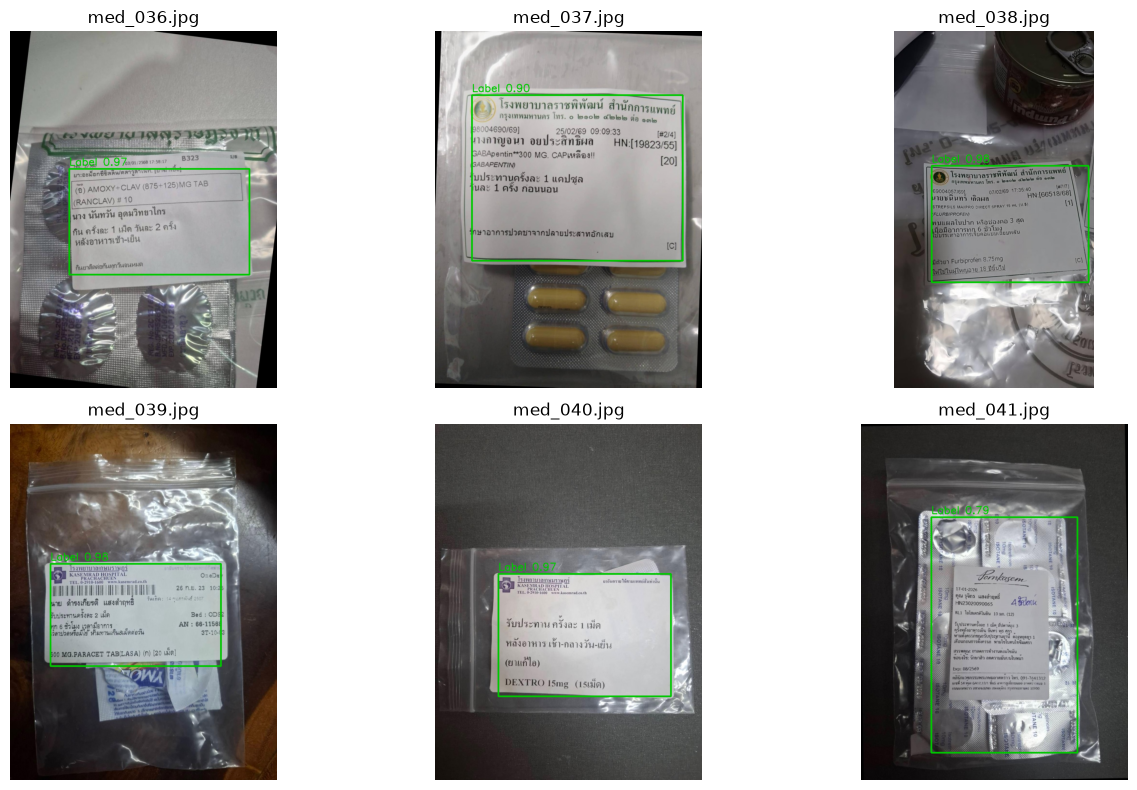

In [5]:
def detect_labels(path, min_score=0.4):
    preds = get_preds(predict(path, MED_ENDPOINT))
    boxes = []
    for p in preds:
        c = p.get("coordinates")
        if c and p.get("score", 0) >= min_score:
            boxes.append((c["xmin"], c["ymin"], c["xmax"], c["ymax"], p["score"]))
    return sorted(boxes, key=lambda b: -b[4])

detections = {path: detect_labels(path) for path in test_imgs}

n = min(6, len(test_imgs))
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, path in zip(axes.flat, test_imgs[:n]):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    for x1, y1, x2, y2, s in detections[path]:
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 200, 0), 4)
        cv2.putText(img, f"Label {s:.2f}", (x1, max(y1 - 10, 20)), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 200, 0), 2)
    ax.imshow(img)
    ax.set_title(os.path.basename(path))
    ax.axis("off")
for ax in axes.flat[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

#### Reading the label

EasyOCR reads the cropped label. From the text:

- **name** - the tallest line of plain words, since the brand name is usually printed biggest
- **strength** - a number followed by mg, mcg, g, ml or IU
- **expiry** and **batch** - whatever follows EXP / Expiry and B.No / Batch / Lot

In [6]:
import easyocr, certifi
# easyocr downloads its models over https, point it at certifi's certs so the download works
os.environ["SSL_CERT_FILE"] = certifi.where()
reader = easyocr.Reader(["th", "en"], gpu=False)

def read_text(img):
    res = reader.readtext(img)
    # top to bottom, left to right
    res.sort(key=lambda r: (r[0][0][1], r[0][0][0]))
    return [(t, abs(b[2][1] - b[0][1])) for b, t, conf in res if conf > 0.3]

def parse_label(lines):
    text = " ".join(t for t, h in lines)

    skip = ("exp", "mfg", "batch", "b.no", "lot", "mrp", "rx", "price")
    cands = [(t, h) for t, h in lines
             if re.match(r"[A-Za-z]{3,}", t.strip()) and not t.lower().startswith(skip)]
    name = max(cands, key=lambda c: c[1])[0].strip() if cands else None

    strength = re.search(r"\b\d+(?:\.\d+)?\s?(?:mg|mcg|g|ml|iu)\b", text, re.I)
    expiry = re.search(r"(?:exp\.?|expiry(?: date)?|use before)\s*[:.]?\s*([0-9]{1,2}\s?[/.\-]\s?[0-9]{2,4}|[a-z]{3}\.?\s?[-/]?\s?[0-9]{2,4})", text, re.I)
    batch = re.search(r"(?:b\.?\s?no\.?|batch(?:\s?no\.?)?|lot)\s*[:.]?\s*([a-z0-9\-]{3,})", text, re.I)

    return {
        "name": name,
        "strength": strength.group(0) if strength else None,
        "expiry": expiry.group(1) if expiry else None,
        "batch": batch.group(1) if batch else None,
        "text": text,
    }

Using CPU. Note: This module is much faster with a GPU.


med_036.jpg


D:\VSCP\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


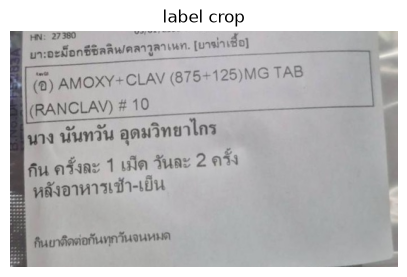

Assistant:
  This looks like amoxx+clav (875+125)m6 ta8.
  OCR text: . ฺ[ยาฆ่าเชื้อ] ยา:อะม็อกซีซิลลิน/คลาวูลาเนท.  amoxx+clav (875+125)m6 ta8  (ranclav) # 10 นันทวัน อุดมวิทยาไกร นาง กิน ครังละ 1 เม็ด วันละ 2 ครึ่ง หลังอาหารเช้า-เยีน กันยาติดต่อกันทุกวันจนหมด

med_037.jpg


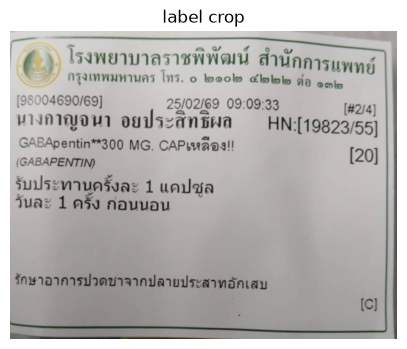

Assistant:
  This looks like gabapentin**300 mg. cap เหลือง!!.
  Strength: 300 mg.
  OCR text: โรงพยาบาลราชพิพัฒน์ สำนักการแพทย์ กรุงเทพมหานคร โทร. ๒๑๑๒ ๔๒๒๒ ต่อ [98004690/69] 25/02/69  09:09:33 [#2/4] นางกาญจนา อยประสิทธิผล hn:[19823/55]  gabapentin**300 mg. cap เหลือง!! [20]  (gabapentin) รับ

med_038.jpg


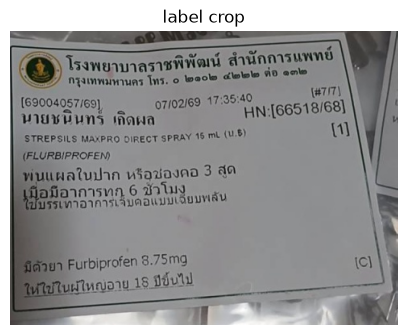

Assistant:
  This looks like strepsils maxpr0 oirect spray 15 ml (u,s).
  Strength: 15 ml.
  OCR text: โรงพยาบาลราชพิพัฒน์ สำนักการแพทย์ ๒oo๒ กรงเทพมทานคร ไทร. [#7/7] 17:35: hn:[66518/68] นานชมี [1] strepsils maxpr0 oirect spray 15 ml (u,s) พนแผลในปาก หรือข่องคอ 3 สูด มิดัวยา furbiprofen 8.75mg  ici



In [7]:
def medicine_assistant(path, show=True):
    img = cv2.imread(path)
    boxes = detections.get(path) or detect_labels(path)

    if boxes:
        x1, y1, x2, y2, s = boxes[0]
        pad = 15
        crop = img[max(y1 - pad, 0):y2 + pad, max(x1 - pad, 0):x2 + pad]
        found = True
    else:
        crop = img      # no label found, read the whole image instead
        found = False

    info = parse_label(read_text(crop))

    if show:
        plt.figure(figsize=(5, 4))
        plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        plt.title("label crop" if found else "no label detected, full image")
        plt.axis("off")
        plt.show()

        print("Assistant:")
        if info["name"]:
            print(f"  This looks like {info['name']}.")
        else:
            print("  I couldn't make out the medicine name clearly.")
        if info["strength"]:
            print(f"  Strength: {info['strength']}.")
        if info["expiry"]:
            print(f"  It expires on {info['expiry']}.")
        if info["batch"]:
            print(f"  Batch number {info['batch']}.")
        print("  OCR text:", info["text"][:200])

    info["label_found"] = found
    return info

for path in test_imgs[:3]:
    print(os.path.basename(path))
    medicine_assistant(path)
    print()

In [8]:
rows = []
for path in test_imgs:
    info = medicine_assistant(path, show=False)
    rows.append({"image": os.path.basename(path), "label_found": info["label_found"],
                 "name": info["name"], "strength": info["strength"],
                 "expiry": info["expiry"], "batch": info["batch"]})

med_df = pd.DataFrame(rows)
print("labels detected:", med_df["label_found"].sum(), "/", len(med_df))
med_df

labels detected: 9 / 9


,image,label_found,name,strength,expiry,batch
0,med_036.jpg,True,amoxx+clav (875+125)m6 ta8,NaN,None,None
1,med_037.jpg,True,gabapentin**300 mg. cap เหลือง!!,300 mg,None,None
2,med_038.jpg,True,"strepsils maxpr0 oirect spray 15 ml (u,s)",15 ml,None,None
3,med_039.jpg,True,ods2,500 mg,None,None
4,med_040.jpg,True,deytr0,NaN,None,None
5,med_041.jpg,True,NaN,NaN,None,None
6,med_042.jpg,True,NaN,NaN,None,None
7,med_043.jpg,True,gabapentin**300 mg. cap เหลือง!!,300 mg,None,None
8,med_044.jpg,True,amoxy+clav (875+125)mg tab,NaN,None,None


The detector found the label on all 9 test images, and cropping it first gives OCR a much cleaner input than the full photo.
The name was readable on 5 of the 9 (Amoxy+Clav, Gabapentin, Strepsils), though OCR slips like "amoxx" or "maxpr0" still show up. On the other 4 it was junk or missing.
Strength was found on 4 of the 9. Expiry and batch were not found on any of them, mainly because these are hospital dispensing labels that print the dispense date and HN number instead of EXP or a batch number.

## Ques 2
### Emotion-aware cognitive assistant using facial expressions

The assistant looks at a face, works out the expression with a classification model trained on LandingLens, and replies in a way that fits the mood.

#### Dataset

FER-2013 from Kaggle (48x48 grayscale faces, 7 emotions). I used 4 of them that are easy to tell apart:
**happy, sad, angry, surprise**. 40 images per class go to LandingLens and 10 per class are kept for testing.
The faces are upscaled to 192x192 since 48x48 is very small for the platform.

In [9]:
# Q2
import kagglehub
fer_path = kagglehub.dataset_download("msambare/fer2013")
print(fer_path, os.listdir(fer_path))

D:\VSCP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\DELL\.cache\kagglehub\datasets\msambare\fer2013\versions\1 ['test', 'train']


In [10]:
emotions = ["happy", "sad", "angry", "surprise"]
n_train, n_test = 40, 10
emo_up = "data/emotion/upload"
emo_test = "data/emotion/test"

for base in (emo_up, emo_test):
    shutil.rmtree(base, ignore_errors=True)

def copy_faces(files, dest):
    os.makedirs(dest)
    for f in files:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (192, 192), interpolation=cv2.INTER_CUBIC)
        cv2.imwrite(os.path.join(dest, os.path.basename(f)), img)

for emo in emotions:
    train_files = random.sample(list_images(os.path.join(fer_path, "train", emo)), n_train)
    test_files = random.sample(list_images(os.path.join(fer_path, "test", emo)), n_test)
    copy_faces(train_files, os.path.join(emo_up, emo))
    copy_faces(test_files, os.path.join(emo_test, emo))
    print(emo, "-> upload:", n_train, " test:", n_test)

happy -> upload: 40  test: 10


sad -> upload: 40  test: 10


angry -> upload: 40  test: 10


surprise -> upload: 40  test: 10


#### Training on LandingLens

- Project type: **Classification**, classes `happy`, `sad`, `angry`, `surprise`
- Uploaded each folder from `data/emotion/upload` and gave all its images that class
- Trained, checked with *Try Model*, then deployed to a cloud endpoint

![training done](as9_images/q2_trained.png)

![try model](as9_images/q2_try_model.png)

#### Testing on the held-out faces

In [11]:
def predict_emotion(path):
    preds = get_preds(predict(path, EMO_ENDPOINT))
    if not preds:
        return None, 0.0
    top = max(preds, key=lambda p: p.get("score", 0))
    return top["labelName"].lower(), top.get("score", 0)

results = []
for emo in emotions:
    for path in list_images(os.path.join(emo_test, emo)):
        pred, score = predict_emotion(path)
        results.append({"image": path, "actual": emo, "predicted": pred, "score": round(score, 3)})

emo_df = pd.DataFrame(results)
acc = (emo_df["actual"] == emo_df["predicted"]).mean()
print(f"accuracy on {len(emo_df)} test faces: {acc:.2%}")
pd.crosstab(emo_df["actual"], emo_df["predicted"], rownames=["actual"], colnames=["predicted"])

accuracy on 40 test faces: 70.00%


predicted,angry,happy,sad,surprise
actual,,,,
angry,6,1,2,1
happy,1,8,0,1
sad,4,2,4,0
surprise,0,0,0,10


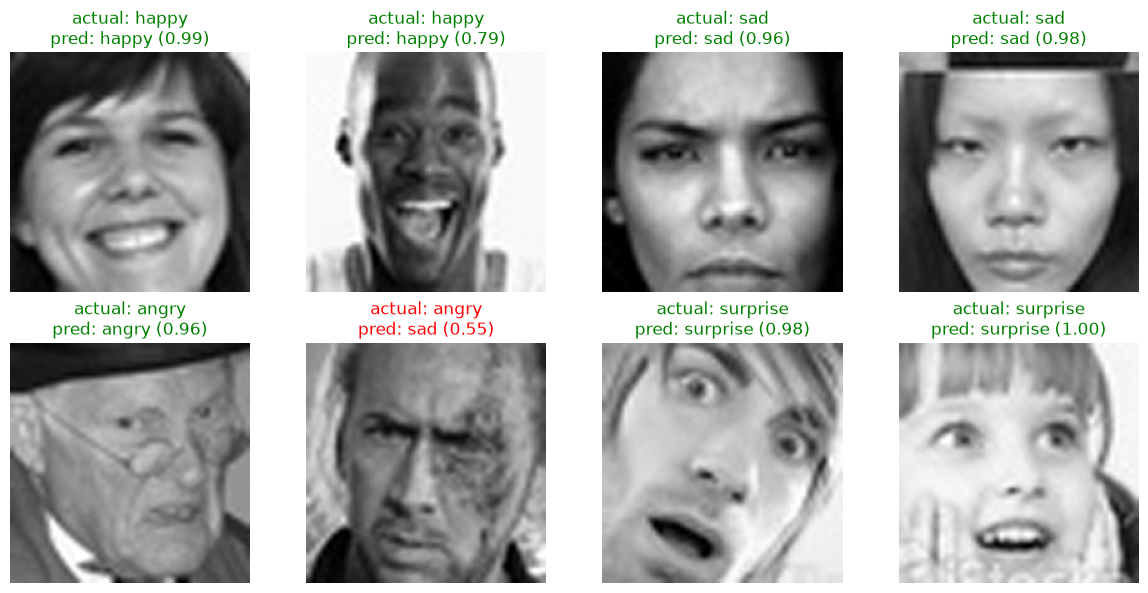

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
picks = emo_df.groupby("actual").head(2).reset_index(drop=True)
for ax, (_, r) in zip(axes.flat, picks.iterrows()):
    ax.imshow(cv2.imread(r["image"], cv2.IMREAD_GRAYSCALE), cmap="gray")
    color = "green" if r["actual"] == r["predicted"] else "red"
    ax.set_title(f"actual: {r['actual']}\npred: {r['predicted']} ({r['score']:.2f})", color=color)
    ax.axis("off")
plt.tight_layout()
plt.show()

#### The assistant

For a normal photo (not a cropped dataset face) the assistant first finds the face with OpenCV's Haar cascade,
crops it, sends only the face to the model, and then replies based on the emotion.

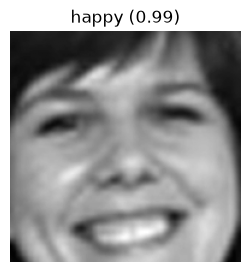

Assistant: You look happy! Want me to play something upbeat to keep the mood going?


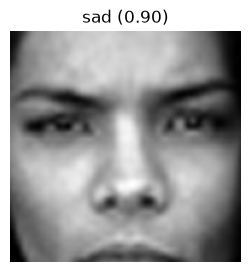

Assistant: You seem a bit low. Want to take a short break, or talk about what's on your mind?


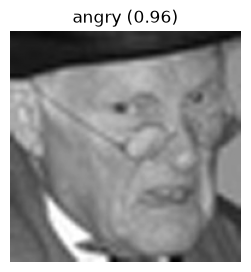

Assistant: You look frustrated. Maybe take a few deep breaths, I can wait.


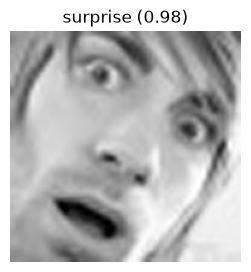

Assistant: Something caught you off guard! Anything you want me to look up?


In [13]:
replies = {
    "happy": "You look happy! Want me to play something upbeat to keep the mood going?",
    "sad": "You seem a bit low. Want to take a short break, or talk about what's on your mind?",
    "angry": "You look frustrated. Maybe take a few deep breaths, I can wait.",
    "surprise": "Something caught you off guard! Anything you want me to look up?",
}

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

def emotion_assistant(path):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))

    if len(faces) > 0:
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
        face = cv2.resize(gray[y:y + h, x:x + w], (192, 192))
    else:
        face = cv2.resize(gray, (192, 192))   # already a face crop

    cv2.imwrite("face_tmp.jpg", face)
    emo, score = predict_emotion("face_tmp.jpg")

    plt.figure(figsize=(3, 3))
    plt.imshow(face, cmap="gray")
    plt.title(f"{emo} ({score:.2f})")
    plt.axis("off")
    plt.show()

    print("Assistant:", replies.get(emo, "I couldn't read your expression clearly, could you face the camera?"))
    return emo

# one test face from each class
for emo in emotions:
    emotion_assistant(list_images(os.path.join(emo_test, emo))[0])

In [14]:
# my own photo
my_photo = "as9_images/my_face.jpg"
if os.path.exists(my_photo):
    emotion_assistant(my_photo)
else:
    print("no photo of my own added yet")

no photo of my own added yet


The model got 70% on the 40 test faces. Surprise was perfect (10/10) and happy was close (8/10), since the mouth changes a lot for both.
Sad was the weakest at 4/10: 4 sad faces were called angry and 2 happy, and 2 angry faces were called sad, so sad and angry are the main mix-up.
FER-2013 faces are tiny and noisy and 40 images per class is a small training set, so more images per class or colour photos should improve this.